# Lab assignment №1, part 3

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the third part of the assignment. First and second parts are waiting for you in the same directory.*__

##  Part 3. SVM and kernels

Kernels concept get adopted in variety of ML algorithms (e.g. Kernel PCA, Gaussian Processes, kNN, ...).

So in this task you are to examine kernels for SVM algorithm applied to rather simple artificial datasets.

To make it clear: we will work with the classification problem through the whole notebook.

In [1]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import numpy as np

Let's generate our dataset and take a look on it.

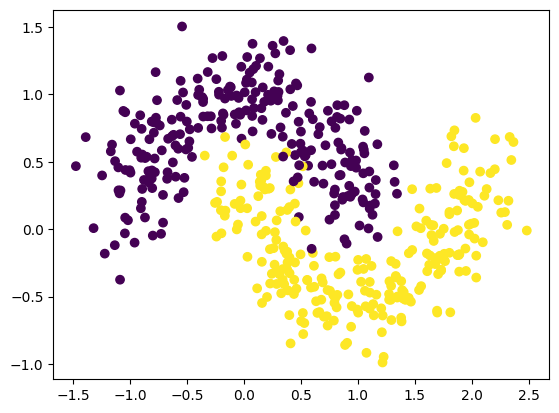

In [2]:
moons_points, moons_labels = make_moons(n_samples=500, noise=0.2, random_state=42)
plt.scatter(moons_points[:, 0], moons_points[:, 1], c=moons_labels)

## 1.1 Pure models.
First let's try to solve this case with good old Logistic Regression and simple (linear kernel) SVM classifier.

Train LR and SVM classifiers (choose params by hand, no CV or intensive grid search neeeded) and plot their decision regions. Calculate one preffered classification metric.

Describe results in one-two sentences.

_Tip:_ to plot classifiers decisions you colud use either sklearn examples ([this](https://scikit-learn.org/stable/auto_examples/neural_networks/plot_mlp_alpha.html#sphx-glr-auto-examples-neural-networks-plot-mlp-alpha-py) or any other) and mess with matplotlib yourself or great [mlxtend](https://github.com/rasbt/mlxtend) package (see their examples for details)

_Pro Tip:_ wirte function `plot_decisions` taking a dataset and an estimator and plotting the results cause you want to use it several times below

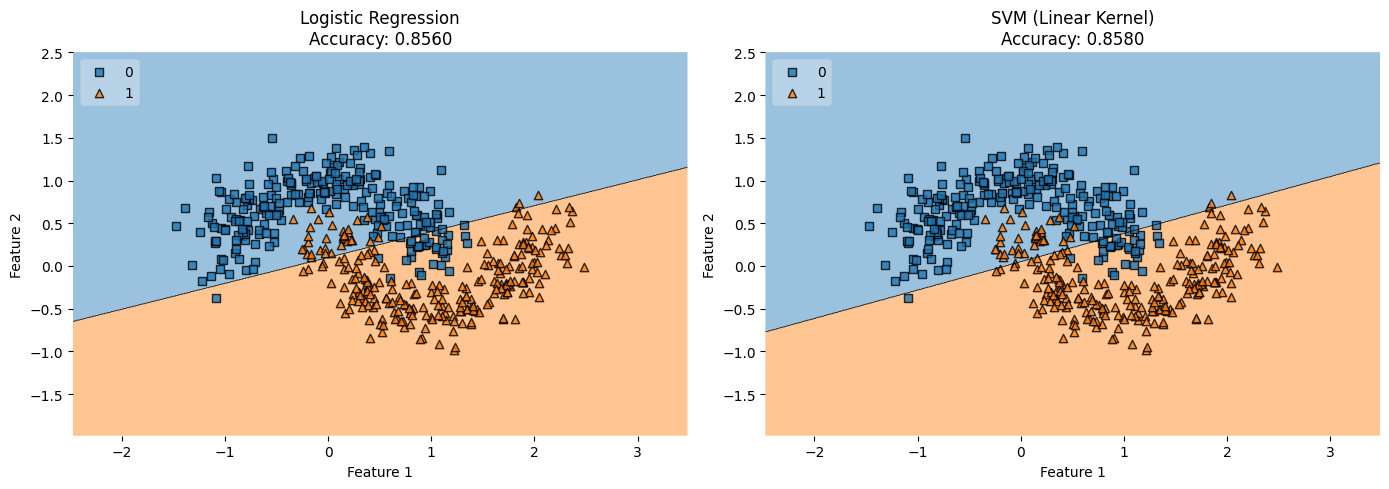

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from mlxtend.plotting import plot_decision_regions

lr = LogisticRegression(C=1.0, max_iter=10) # add some params
svm = SVC(kernel='linear', C=1.0) # here too

### YOUR CODE HERE
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

def plot_decisions(X, y, clf, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    clf.fit(X, y)
    y_pred = clf.predict(X)
    acc = accuracy_score(y, y_pred)
    plot_decision_regions(X, y, clf=clf, legend=2, ax=ax)
    ax.set_title(f"{title}\nAccuracy: {acc:.4f}")
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')



fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_decisions(moons_points, moons_labels, lr, "Logistic Regression", ax=axes[0])
plot_decisions(moons_points, moons_labels, svm, "SVM (Linear Kernel)", ax=axes[1])
plt.tight_layout()
plt.show()

**Описание**

Из-за характерного датасета эти линейные модели сталкиваются с высоким смещениеми и не могут выучить истинную структуру данных. Изменение параметра регуляризации C не улучшит результат, так как гиперплоскость не способна эффективно разделить переплетенные классы. На маленьком датасете в 500 точек max_iter достаточно 10

## 1.2 Kernel tirck

Now use different kernels (`poly`, `rbf`, `sigmoid`) on SVC to get better results. Play `degree` parameter and others.

For each kernel estimate optimal params, plot decision regions, calculate metric you've chosen eariler.

Write couple of sentences on:

* What have happenned with classification quality?
* How did decision border changed for each kernel?
* What `degree` have you chosen and why?

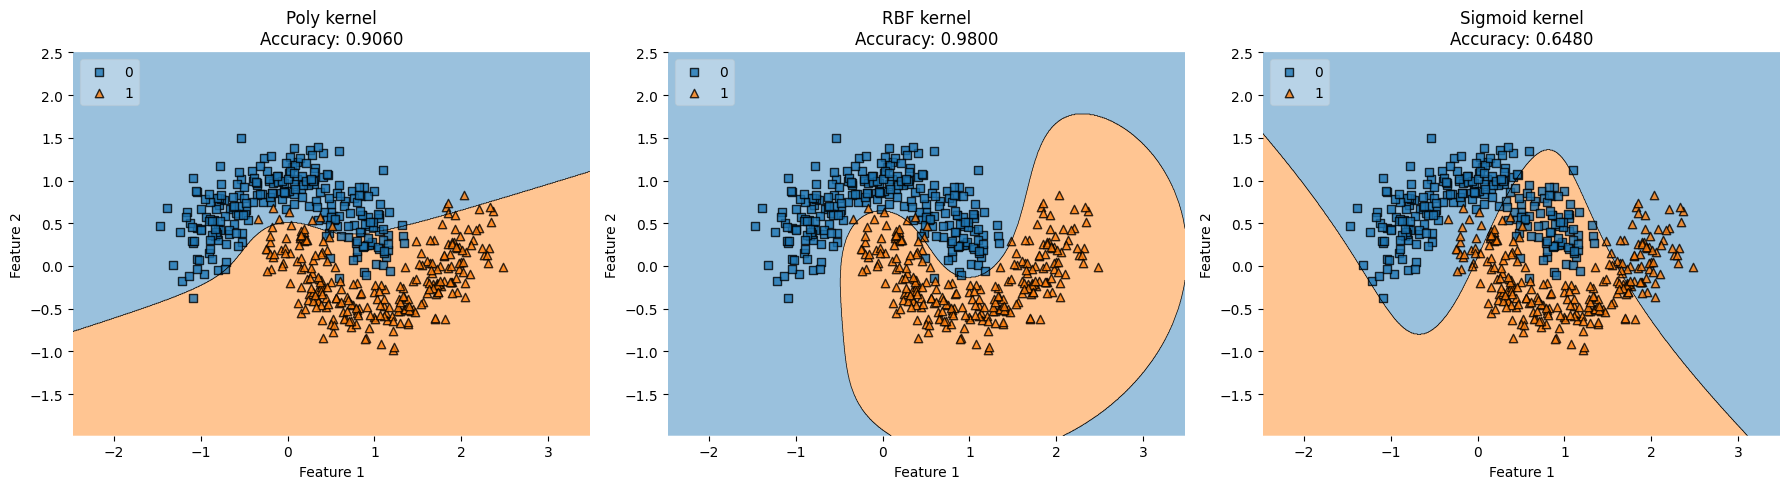

In [4]:
### YOUR CODE HERE

svm_poly = SVC(kernel='poly', degree=3, C=1)

svm_rbf = SVC(kernel='rbf', C=10, gamma='scale')

svm_sigmoid = SVC(kernel='sigmoid', C=1, gamma='scale')


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_decisions(moons_points, moons_labels, svm_poly, "Poly kernel", ax=axes[0])
plot_decisions(moons_points, moons_labels, svm_rbf, "RBF kernel", ax=axes[1])
plot_decisions(moons_points, moons_labels, svm_sigmoid, "Sigmoid kernel", ax=axes[2])
plt.tight_layout()
plt.show()

**Описание**

Использование нелинейных ядер повысило точность с ~0.86 до ~0.98 (при С=10). Модель RBF смогла эффективно разделить переплетенные классы.

poly (полиномиальное) - граница стала гладкой изогнутой кривой, напоминающей параболу. Хороший результат по точности

rbf (радиальное) - построило наиболее гибкую границу. Она идеально разделила луны, создав плавные замкнутые области вокруг классов. Это лучший результат.

sigmoid - показало худший результат (точность упала до ~0.65). Граница стала гиперболической формы, которая плохо соответствует структуре данных.

Я выбрал degree=3 для poly. Это оптимальное значение которое дает нужную кривизну без переобучения.

degree=2 слишком простая (модель недообучается, не может захватить изгиб).

degree=4 и выше модель просто хуже подходит.

## 1.3 Simpler solution (of a kind)
What is we could use Logisitc Regression to successfully solve this task?

Feature generation is a thing to help here. Different techniques of feature generation are used in real life, couple of them will be covered in additional lectures.

In particular case simple `PolynomialFeatures` ([link](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)) are able to save the day.

Generate the set of new features, train LR on it, plot decision regions, calculate metric.

* Comare SVM's results with this solution (quality, borders type)
* What degree of PolynomialFeatures have you used? Compare with same SVM kernel parameter.

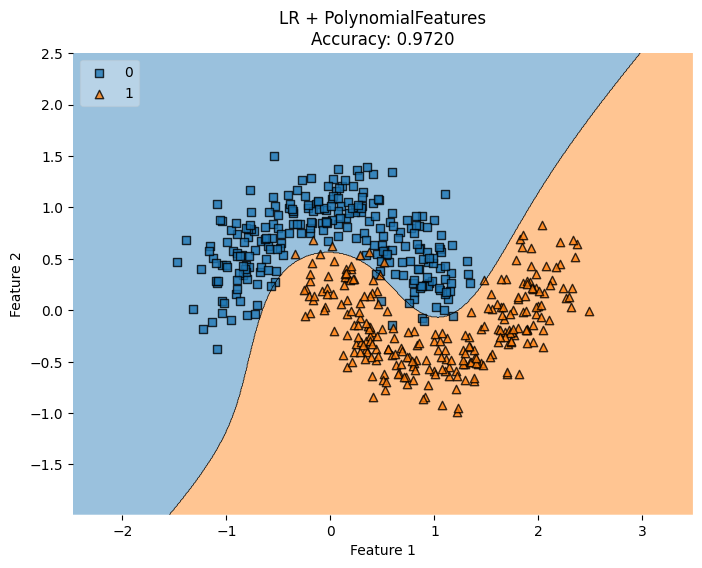

In [5]:
from sklearn.preprocessing import PolynomialFeatures

### YOUR CODE HERE
from sklearn.pipeline import make_pipeline

poly_lr = make_pipeline(PolynomialFeatures(degree=5), LogisticRegression(C=1.0, max_iter=1000))


fig, ax = plt.subplots(figsize=(8, 6))
plot_decisions(moons_points, moons_labels, poly_lr, "LR + PolynomialFeatures", ax=ax)
plt.show()

**Описание**

Качество модели (Accuracy) достигло ~0.97, что практически идентично результату с RBF в 1.2 (при с=10 и gamma='scale'). Тип границы также совпадает - обе модели построили гладкую изогнутую кривую, которая идеально разделила луны.

Я использовал degree=5. Это отлично от poly в 1.2. Но если и тут взять degree=3, то точность практически не упадет (0.968 против 0.972 для deg=5).

PolynomialFeatures, переводит двумерные данные в пространство более высокой размерности (добавляет признаки $x_1^2$, $x_2^2, \ldots$). В новом многомерном пространстве классы становятся линейно разделимыми. Логистическая регрессия проводит там гиперплоскость, проецируем обратно в двумерное представление и получаем изогнутую кривую.

Poly kernel делает то же самое математически, но благодаря Kernel trick не нужно создавать новые признаки - он вычисляет скалярные произведения напрямую, это экономит память и время на больших данных.

## 1.4 Harder problem

Let's make this task a bit more challenging via upgrading dataset:

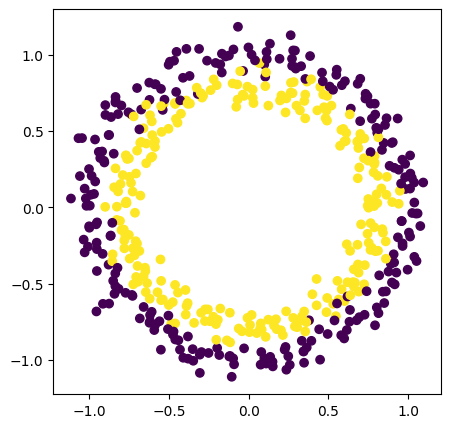

In [6]:
from sklearn.datasets import make_circles

circles_points, circles_labels = make_circles(n_samples=500, noise=0.06, random_state=42)

plt.figure(figsize=(5, 5))
plt.scatter(circles_points[:, 0], circles_points[:, 1], c=circles_labels)

And even more:

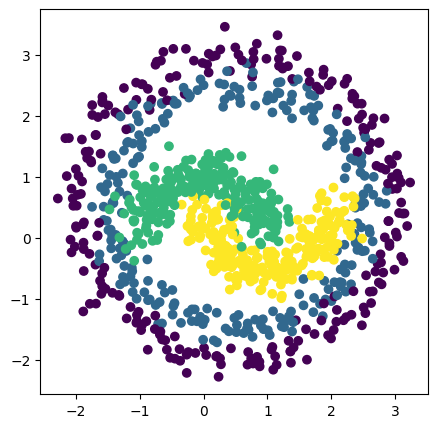

In [7]:
points = np.vstack((circles_points*2.5 + 0.5, moons_points))
labels = np.hstack((circles_labels, moons_labels + 2)) # + 2 to distinct moons classes

plt.figure(figsize=(5, 5))
plt.scatter(points[:, 0], points[:, 1], c=labels)

Now do your best using all the approaches above!

Tune LR with generated features, SVM with appropriate kernel of your choice. You may add some of your loved models to demonstrate their (and your) strength. Again plot decision regions, calculate metric.

Justify the results in a few phrases.

/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


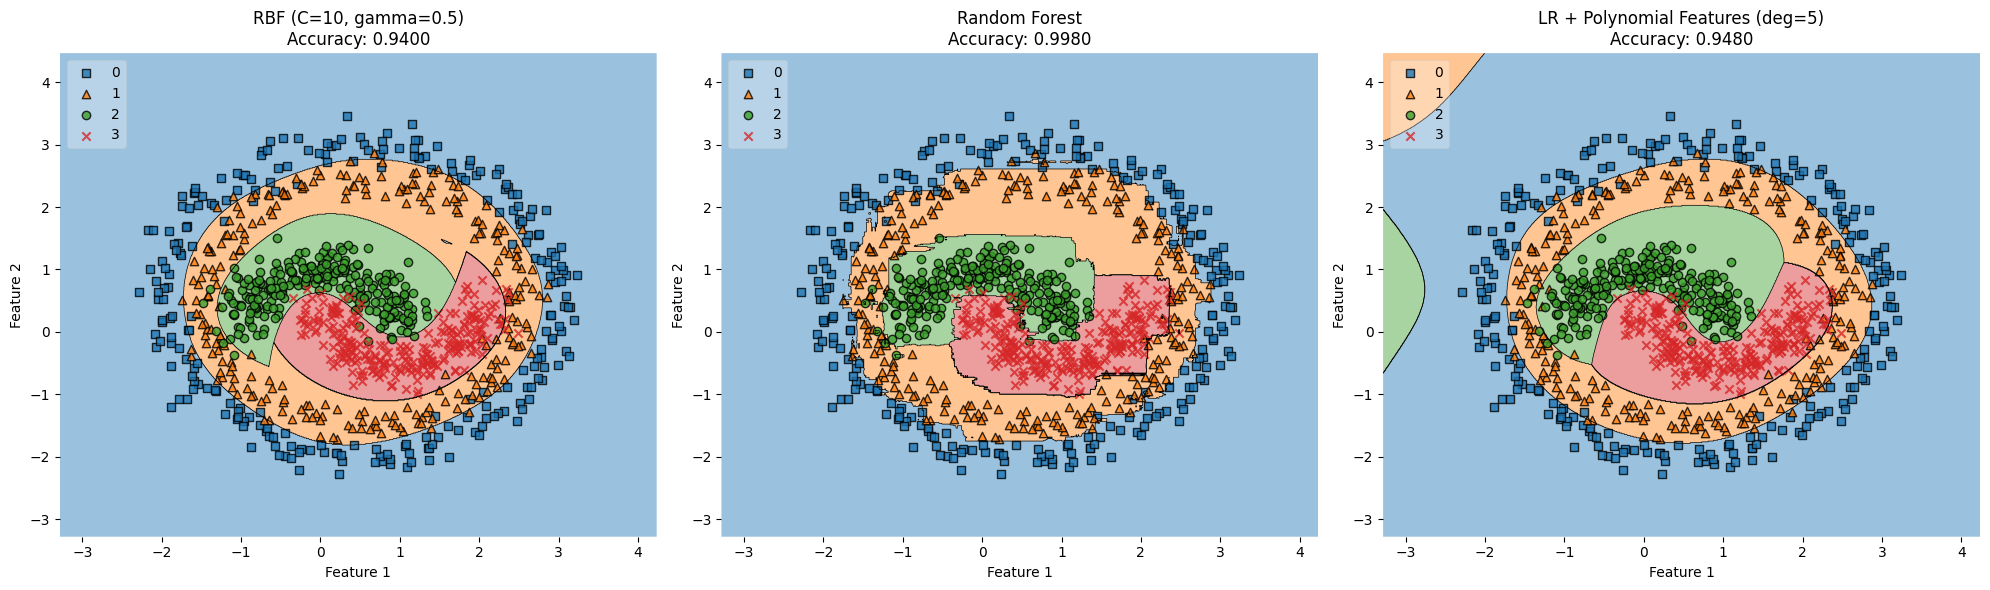

In [8]:
### YOUR CODE HERE
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

svm_rbf_hard = SVC(kernel='rbf', C=10, gamma=0.5, random_state=42)

rf_hard = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=13)

poly_lr_hard = make_pipeline(PolynomialFeatures(degree=5), LogisticRegression(C=10, max_iter=10000))


fig, axes = plt.subplots(1, 3, figsize=(20, 6))
plot_decisions(points, labels, svm_rbf_hard, "RBF (C=10, gamma=0.5)", ax=axes[0])
plot_decisions(points, labels, rf_hard, "Random Forest", ax=axes[1])
plot_decisions(points, labels, poly_lr_hard, "LR + Polynomial Features (deg=5)", ax=axes[2])
plt.tight_layout()
plt.show()

**Описание**

Сравнил три подхода: SVM с RBF-ядром (C=10, gamma=0.5), Random Forest (max_depth=10) и логистическую регрессию с полиномиальными признаками (degree=5).

Random Forest строит границу из прямоугольных ступенек, потому что разбивает пространство по осям. Лес почти идеально подгоняется под обучающие точки, но это следствие переобучения.  На графике видны мелкие "островки" класса 1, а границы между классами 2 и 3 идут "рвано". Для таких данных с гладкими круговыми границами деревья неудобны.


SVM с RBF и LR+poly построили гладкие границы между четырьмя классами, которые лучше соответствуют форме данных, а качество у них практически одинаковое. RBF-ядро подходит для данных, где классы образуют замкнутые области (кольца и луны), а LR+poly достигает того же результата через увеличение числа признаков. Недостаток LR+poly виден на графике - слева и в левом верхнем углу за пределами данных появились лишние области класса 1 и 2.

Итог: лучшими оказались SVM с RBF-ядром и LR+Poly, а Random Forest переобучился.